# GSE193531 — Step 5: Malignant vs. Normal Plasma-Cell Classification

Re-attaches the original study's per-cell `normal_or_neoplastic` label
(present in the raw GEO metadata but never carried into any processed
object) and uses it as the primary malignant/normal call. Immunoglobulin
kappa/lambda light-chain restriction — computed independently from raw UMI
counts — is used as an **orthogonal, sample-level** QC check, not as a
second vote that can override the primary label. Does **not** build
pseudobulk or run differential expression — that is notebook 6.

**Caveat:** the original study's method for assigning `normal_or_neoplastic`
is not documented in anything available to this pipeline. It is treated here
as the best available ground truth for this cohort, not as an
independently-validated label — the kappa/lambda check below is exactly the
check on that trust.

**Kappa/lambda restriction is a sample-level, not a cell-level, comparison.**
A malignant plasma-cell clone is, by definition, a *population* phenomenon:
one cell's own dominant light chain says nothing about malignancy on its
own, but a sample's mixture of light chains across its cells does. So this
notebook does not build a per-cell "kappa/lambda malignancy call" and
compare it cell-by-cell against `normal_or_neoplastic`. Instead, for each
sample, the fraction of its cells labeled `Neoplastic` is compared against
that sample's kappa/lambda composition, continuously.

**Input:**
- `data/processed/GSE193531/GSE193531_plasma_cells.h5ad` (from notebook 04)
- `data/raw/GSE193531/GSE193531_cell-level-metadata.csv`

**Output:**
- `data/processed/GSE193531/GSE193531_plasma_cells_classified.h5ad`
- `results/GSE193531/malignant_normal_classification/GSE193531_sample_light_chain_qc.csv`
- `results/GSE193531/malignant_normal_classification/GSE193531_malignancy_counts_per_sample.csv`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
from scipy.stats import spearmanr

import matplotlib.pyplot as plt

sc.settings.verbosity = 1

#### Directory layout and required files

In [2]:
PROJECT = Path("../")
COHORT = "GSE193531"

RAW_DIR = PROJECT / "data" / "raw" / COHORT
PROCESSED_DIR = PROJECT / "data" / "processed" / COHORT
RESULTS_DIR = PROJECT / "results" / COHORT

(RESULTS_DIR / "malignant_normal_classification").mkdir(parents=True, exist_ok=True)

INPUT_H5AD = PROCESSED_DIR / f"{COHORT}_plasma_cells.h5ad"
if not INPUT_H5AD.exists():
    raise FileNotFoundError(INPUT_H5AD)

CELL_METADATA_FILE = RAW_DIR / f"{COHORT}_cell-level-metadata.csv"
if not CELL_METADATA_FILE.exists():
    raise FileNotFoundError(CELL_METADATA_FILE)

OUTPUT_H5AD = PROCESSED_DIR / f"{COHORT}_plasma_cells_classified.h5ad"

## Load Plasma-Cell Subset

In [3]:
adata = sc.read_h5ad(INPUT_H5AD)
print(adata)

if not (adata.obs["cell_type"] == "Plasma_cell").all():
    raise ValueError("Expected every cell in this object to be labeled cell_type == 'Plasma_cell'.")

if "counts" not in adata.layers:
    raise KeyError("adata.layers['counts'] not found -- the raw counts layer is required for kappa/lambda calling.")

counts_sample = adata.layers["counts"][:500]
counts_sample = counts_sample.toarray() if hasattr(counts_sample, "toarray") else np.asarray(counts_sample)
if not np.allclose(counts_sample, np.round(counts_sample)):
    raise ValueError("adata.layers['counts'] does not look like raw integer counts.")

print(f"\nConfirmed: {adata.n_obs:,} cells, all cell_type == 'Plasma_cell', raw counts layer intact.")

AnnData object with n_obs × n_vars = 17500 × 22273
    obs: 'sample_id', 'patient_id', 'clinical_stage_standard', 'n_genes', 'doublet_score', 'predicted_doublet', 'n_counts', 'pct_mito', 'pct_ribo', 'pct_hb', 'pct_ig', 'complexity', 'leiden', 'cell_type_candidate', 'Plasma_cell_score', 'B_cell_score', 'CD4_T_score', 'CD8_T_score', 'NK_cell_score', 'Myeloid_score', 'pDC_score', 'Erythroid_score', 'cell_type', 'marker_positive', 'cluster_call', 'plasma_cell_confirmed'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cell_type_candidate_colors', 'cell_type_colors', 'clinical_stage_standard_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'sample_id_colors', 'scrublet', 'umap'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

Confirmed: 17,500 cells, all cell_type == 'Plasma_cell', raw counts layer intact.


## Re-Attach the Original Study's `normal_or_neoplastic` Label

The QC notebook only ever pulled `sample_ID` and `disease_stage` from the
raw metadata, so this label was never carried into any processed `.h5ad`
and is re-attached here by joining on cell ID.

In [4]:
raw_metadata = pd.read_csv(CELL_METADATA_FILE)
raw_metadata = raw_metadata.rename(columns={"index": "cell_id"})

if "cell_id" not in raw_metadata.columns:
    raise KeyError("Expected an 'index' column (renamed to 'cell_id') in the raw cell-level metadata.")
if "normal_or_neoplastic" not in raw_metadata.columns:
    raise KeyError("Expected column 'normal_or_neoplastic' not found in the raw cell-level metadata.")

raw_metadata = raw_metadata.set_index("cell_id")

print("Raw normal_or_neoplastic value counts (cohort-wide, before any filtering or standardization):")
print(raw_metadata["normal_or_neoplastic"].value_counts(dropna=False))

Raw normal_or_neoplastic value counts (cohort-wide, before any filtering or standardization):
normal_or_neoplastic
neoplastic    18988
normal        10379
NaN              20
Name: count, dtype: int64


In [5]:
missing_from_raw = set(adata.obs_names) - set(raw_metadata.index)
if missing_from_raw:
    raise ValueError(f"{len(missing_from_raw)} plasma cells have no matching row in the raw cell-level metadata.")

adata.obs["normal_or_neoplastic_raw"] = raw_metadata.loc[adata.obs_names, "normal_or_neoplastic"]

print("normal_or_neoplastic_raw, restricted to the confirmed plasma-cell subset:")
print(adata.obs["normal_or_neoplastic_raw"].value_counts(dropna=False))

normal_or_neoplastic_raw, restricted to the confirmed plasma-cell subset:
normal_or_neoplastic_raw
neoplastic    9674
normal        7814
NaN             12
Name: count, dtype: int64


In [6]:
# Standardized to a fixed Normal/Neoplastic vocabulary, case- and whitespace-insensitive.
NEOPLASTIC_LABEL_MAP = {"normal": "Normal", "neoplastic": "Neoplastic"}

raw = adata.obs["normal_or_neoplastic_raw"]
originally_missing = raw.isna()

cleaned = raw.str.strip().str.lower()
mapped = cleaned.map(NEOPLASTIC_LABEL_MAP)

truly_unrecognized = mapped.isna() & cleaned.notna()
if truly_unrecognized.any():
    bad_values = sorted(cleaned[truly_unrecognized].unique())
    raise ValueError(
        f"Unrecognized normal_or_neoplastic label(s) in the raw metadata: {bad_values}. "
        "Update NEOPLASTIC_LABEL_MAP above to cover these exact raw values before proceeding."
    )

print(f"Cells with a missing (NaN) normal_or_neoplastic label in the raw metadata: "
      f"{int(originally_missing.sum())} / {adata.n_obs:,}")
if originally_missing.any():
    print("Missing-label cells, by sample_id / clinical_stage_standard:")
    display(adata.obs.loc[originally_missing, ["sample_id", "clinical_stage_standard"]].value_counts().rename("n_cells"))

adata.obs["normal_or_neoplastic"] = mapped.fillna("Unknown")

print()
print("Standardized normal_or_neoplastic (plasma-cell subset):")
print(adata.obs["normal_or_neoplastic"].value_counts(dropna=False))

Cells with a missing (NaN) normal_or_neoplastic label in the raw metadata: 12 / 17,500
Missing-label cells, by sample_id / clinical_stage_standard:


sample_id  clinical_stage_standard
MGUS-2     MGUS                       12
Name: n_cells, dtype: int64


Standardized normal_or_neoplastic (plasma-cell subset):
normal_or_neoplastic
Neoplastic    9674
Normal        7814
Unknown         12
Name: count, dtype: int64


## Kappa / Lambda Light-Chain Calling

Raw counts are used rather than log-normalized values, since this is a
per-cell UMI-count comparison, not an expression-level test. A cell's
dominant light chain is whichever has the higher raw UMI count; a cell with
zero UMIs for both is `Undetected` rather than forced into a call.

In [7]:
KAPPA_GENE = "IGKC"
LAMBDA_GENE_CANDIDATES = ["IGLC1", "IGLC2", "IGLC3", "IGLC4", "IGLC5", "IGLC6", "IGLC7"]

kappa_present = KAPPA_GENE in adata.var_names
lambda_present = [g for g in LAMBDA_GENE_CANDIDATES if g in adata.var_names]

if not kappa_present:
    raise KeyError(f"{KAPPA_GENE} not found in this cohort's gene set -- cannot compute kappa/lambda restriction.")
if not lambda_present:
    raise KeyError("No lambda constant-region genes (IGLC1-IGLC7) found in this cohort's gene set.")

print(f"Kappa constant gene: {KAPPA_GENE}")
print(f"Lambda constant gene(s) present: {lambda_present}")

counts = adata.layers["counts"]
kappa_idx = adata.var_names.get_loc(KAPPA_GENE)
kappa_counts = counts[:, kappa_idx]
kappa_counts = kappa_counts.toarray().ravel() if hasattr(kappa_counts, "toarray") else np.asarray(kappa_counts).ravel()

lambda_idx = [adata.var_names.get_loc(g) for g in lambda_present]
lambda_counts_matrix = counts[:, lambda_idx]
lambda_counts_matrix = lambda_counts_matrix.toarray() if hasattr(lambda_counts_matrix, "toarray") else np.asarray(lambda_counts_matrix)
lambda_counts = lambda_counts_matrix.sum(axis=1)

adata.obs["kappa_counts"] = np.asarray(kappa_counts).ravel()
adata.obs["lambda_counts"] = np.asarray(lambda_counts).ravel()

adata.obs["light_chain_call"] = np.select(
    [
        (adata.obs["kappa_counts"] == 0) & (adata.obs["lambda_counts"] == 0),
        adata.obs["kappa_counts"] > adata.obs["lambda_counts"],
        adata.obs["lambda_counts"] > adata.obs["kappa_counts"],
    ],
    ["Undetected", "Kappa", "Lambda"],
    default="Tied",
)

print("Per-cell light_chain_call:")
print(adata.obs["light_chain_call"].value_counts())

Kappa constant gene: IGKC
Lambda constant gene(s) present: ['IGLC2', 'IGLC3', 'IGLC4', 'IGLC5', 'IGLC6', 'IGLC7']
Per-cell light_chain_call:
light_chain_call
Kappa         11417
Lambda         6070
Undetected       12
Tied              1
Name: count, dtype: int64


## Kappa/Lambda Sample-Level Clonality QC

For each sample: `neoplastic_fraction` (fraction labeled `Neoplastic` by the
primary label), `kappa_fraction`/`lambda_fraction`, and `restriction_score`
= `max(kappa_fraction, lambda_fraction)` — `0.5` is perfectly mixed
(polyclonal-looking), `1.0` is completely one chain (monoclonal-looking). No
threshold is applied to turn this into a category; it is QC on the primary
label, not a competing label.

In [8]:
sample_qc = (
    adata.obs.groupby(["patient_id", "sample_id", "clinical_stage_standard"], observed=True)
    .agg(
        n_cells=("normal_or_neoplastic", "size"),
        neoplastic_fraction=("normal_or_neoplastic", lambda s: (s == "Neoplastic").mean()),
    )
    .reset_index()
)

callable_mask = adata.obs["light_chain_call"].isin(["Kappa", "Lambda"])
print(f"Cells with a definite light-chain call: {int(callable_mask.sum()):,} / {adata.n_obs:,} ({callable_mask.mean():.2%})")

light_chain_fractions = (
    adata.obs.loc[callable_mask]
    .groupby("sample_id", observed=True)["light_chain_call"]
    .value_counts(normalize=True)
    .unstack(fill_value=0.0)
    .reset_index()
)
for col in ["Kappa", "Lambda"]:
    if col not in light_chain_fractions.columns:
        light_chain_fractions[col] = 0.0
light_chain_fractions = light_chain_fractions.rename(columns={"Kappa": "kappa_fraction", "Lambda": "lambda_fraction"})

sample_qc = sample_qc.merge(light_chain_fractions, on="sample_id", how="left")
sample_qc["restriction_score"] = sample_qc[["kappa_fraction", "lambda_fraction"]].max(axis=1)
sample_qc = sample_qc.sort_values(["clinical_stage_standard", "sample_id"])

display(sample_qc.round(3))

Cells with a definite light-chain call: 17,487 / 17,500 (99.93%)


,patient_id,sample_id,clinical_stage_standard,n_cells,neoplastic_fraction,kappa_fraction,lambda_fraction,restriction_score
14,NBM-1,NBM-1,Healthy,655,0.000,0.641,0.359,0.641
15,NBM-2,NBM-2,Healthy,759,0.000,0.557,0.443,0.557
16,NBM-3,NBM-3,Healthy,46,0.000,0.630,0.370,0.630
17,NBM-4,NBM-4,Healthy,134,0.000,0.582,0.418,0.582
18,NBM-6,NBM-6,Healthy,630,0.000,0.560,0.440,0.560
19,NBM-7,NBM-7,Healthy,1480,0.000,0.570,0.430,0.570
20,NBM-8,NBM-8,Healthy,41,0.000,0.512,0.488,0.512
21,NBM-10,NBM-10,Healthy,2491,0.000,0.513,0.487,0.513
22,NBM-11,NBM-11,Healthy,764,0.000,0.624,0.376,0.624
0,MGUS-1,MGUS-1,MGUS,115,0.000,0.635,0.365,0.635


Spearman correlation, neoplastic_fraction vs. restriction_score across samples: rho=0.913, p=2.23e-14


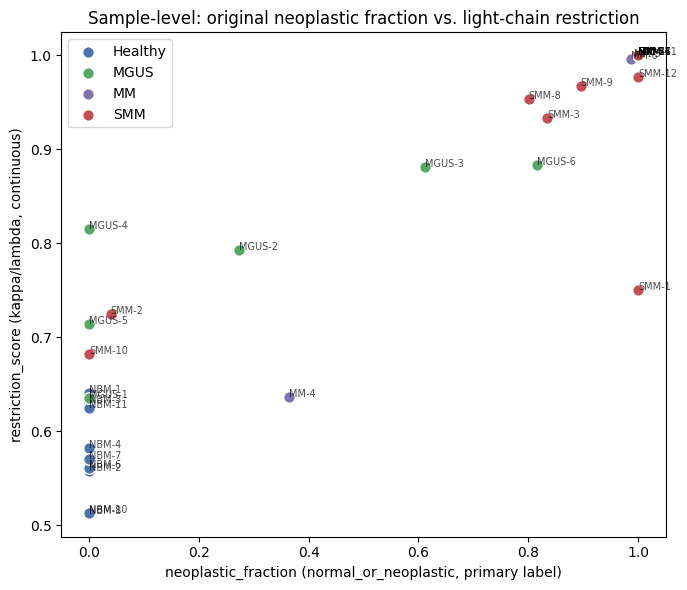

In [9]:
rho, pval = spearmanr(sample_qc["neoplastic_fraction"], sample_qc["restriction_score"])
print(f"Spearman correlation, neoplastic_fraction vs. restriction_score across samples: rho={rho:.3f}, p={pval:.3g}")

plt.figure(figsize=(7, 6))
stage_colors = {"Healthy": "#4C72B0", "MGUS": "#55A868", "SMM": "#C44E52", "MM": "#8172B2"}
for stage_name, group in sample_qc.groupby("clinical_stage_standard", observed=True):
    plt.scatter(group["neoplastic_fraction"], group["restriction_score"],
                label=stage_name, color=stage_colors.get(stage_name), s=70, edgecolor="white")
for _, row in sample_qc.iterrows():
    plt.annotate(row["sample_id"], (row["neoplastic_fraction"], row["restriction_score"]), fontsize=7, alpha=0.7)
plt.xlabel("neoplastic_fraction (normal_or_neoplastic, primary label)")
plt.ylabel("restriction_score (kappa/lambda, continuous)")
plt.title("Sample-level: original neoplastic fraction vs. light-chain restriction")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
sample_qc_path = RESULTS_DIR / "malignant_normal_classification" / f"{COHORT}_sample_light_chain_qc.csv"
sample_qc.to_csv(sample_qc_path, index=False)
print(f"Saved sample-level light-chain QC table -> {sample_qc_path}")

Saved sample-level light-chain QC table -> ../results/GSE193531/malignant_normal_classification/GSE193531_sample_light_chain_qc.csv


## Final Malignancy Label

`adata.obs["malignancy_status"] = adata.obs["normal_or_neoplastic"]` — the
re-attached original-study label is used as-is for every cell, including
`Healthy` samples and any cell whose raw label was missing (now
`"Unknown"`). The sample-level kappa/lambda comparison above is reported,
not used to overrule the primary label.

In [11]:
adata.obs["malignancy_status"] = adata.obs["normal_or_neoplastic"]

print("Final malignancy_status:")
print(adata.obs["malignancy_status"].value_counts())

Final malignancy_status:
malignancy_status
Neoplastic    9674
Normal        7814
Unknown         12
Name: count, dtype: int64


## Malignant / Normal Counts per Patient / Sample

In [12]:
malignancy_counts = (
    adata.obs.groupby(["patient_id", "sample_id", "clinical_stage_standard"], observed=True)["malignancy_status"]
    .value_counts()
    .unstack(fill_value=0)
    .reset_index()
)
malignancy_counts = malignancy_counts.sort_values(["clinical_stage_standard", "sample_id"])

malignancy_counts_path = RESULTS_DIR / "malignant_normal_classification" / f"{COHORT}_malignancy_counts_per_sample.csv"
malignancy_counts.to_csv(malignancy_counts_path, index=False)

print(f"Saved per-sample malignancy counts -> {malignancy_counts_path}")
display(malignancy_counts)

Saved per-sample malignancy counts -> ../results/GSE193531/malignant_normal_classification/GSE193531_malignancy_counts_per_sample.csv


malignancy_status,patient_id,sample_id,clinical_stage_standard,Neoplastic,Normal,Unknown
14,NBM-1,NBM-1,Healthy,0,655,0
15,NBM-2,NBM-2,Healthy,0,759,0
16,NBM-3,NBM-3,Healthy,0,46,0
17,NBM-4,NBM-4,Healthy,0,134,0
18,NBM-6,NBM-6,Healthy,0,630,0
19,NBM-7,NBM-7,Healthy,0,1480,0
20,NBM-8,NBM-8,Healthy,0,41,0
21,NBM-10,NBM-10,Healthy,0,2491,0
22,NBM-11,NBM-11,Healthy,0,764,0
0,MGUS-1,MGUS-1,MGUS,0,115,0


## Save Classified Plasma-Cell Object

In [13]:
adata.write(OUTPUT_H5AD)

print(f"Saved classified plasma-cell object: {OUTPUT_H5AD}")
print(f"Cells: {adata.n_obs:,}  Genes: {adata.n_vars:,}")
print(adata.obs["malignancy_status"].value_counts())

Saved classified plasma-cell object: ../data/processed/GSE193531/GSE193531_plasma_cells_classified.h5ad
Cells: 17,500  Genes: 22,273
malignancy_status
Neoplastic    9674
Normal        7814
Unknown         12
Name: count, dtype: int64
